# Task 3 — Cold-target generalisation on KIBA

**Question.** For a kinase never seen in training, how well can we predict each ligand's KIBA score
from the target's amino-acid sequence (plus ligand information)? Ligands are users and targets are
items, as in Task 2. Every test target is unseen, so no target-ID or target-mean features are used.

This notebook follows the shared Task 3 plan used for DAVIS (`davis_task3_cold_target.ipynb`):
same split rule, features, model family, grid, metrics and seeds. KIBA-specific changes are marked
**[KIBA]**, and one extra model (a similarity-weighted neighbour predictor) is marked **[new]**.

**Outputs**
- `results/kiba/task3_*.csv|md`: every table shown below
- `figures/kiba/task3_*.png`: every figure shown below
- `data/processed/kiba_esm2_t6_8M.npy`: cached ESM-2 embeddings (229 × 320)

In [1]:
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "kiba"
OUT = ROOT / "data" / "processed"
FIG = ROOT / "figures" / "kiba"
RES = ROOT / "results" / "kiba"
for p in (FIG, RES):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)

# Same plot style as Task 1.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e5e2"
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

GROUP_COL = "target_group"
SHARES = (0.70, 0.85)
MAIN_SEED, SEEDS = 42, [0, 1, 2, 3, 4]
FAMILY_CUT = 0.5      # [KIBA] targets joined at average Smith–Waterman similarity > 0.5 form one group
FLOOR = 11.2          # [KIBA] heaped values 11.1 / 11.2 (22.9 % of pairs, Task 1); stands in for DAVIS's pKd = 5
CI_MAX = 20_000       # [KIBA] CI is O(n^2): evaluate on at most 20,000 pairs (fixed seed)
HIT_MIN = 5           # Hit@k only for ligands with >= 5 held-out observed targets
SVD_DIM, FP_DIM, ESM_DIM = 24, 16, 24
GRID_HP = [dict(max_depth=d, learning_rate=lr, max_iter=it) for d in (3, 5) for lr, it in ((0.05, 300), (0.1, 150))]


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


def save_table(df, name, index=False):
    df.to_csv(RES / f"{name}.csv", index=index)
    (RES / f"{name}.md").write_text(df.to_markdown(index=index, floatfmt=".3f"), encoding="utf-8")
    return df

## 1. Load and check

We start from the cleaned long table of Task 1 (`kiba_pairs_clean.csv`): stereoisomer IDs that share a
canonical SMILES are merged, giving **2,068 ligands × 229 targets and 117,657 observed pairs**. Only
observed pairs are used. Missing pairs are unknown, not non-binding.

**[KIBA] Target groups.** KIBA has one sequence per UniProt ID, so no variant groups are given. We
cluster targets with the supplied Smith–Waterman similarity matrix (`kiba_target_sim.txt`), using
average linkage cut at similarity 0.5. These are the same kinase families shown in Task 1 Fig. 7.
Clustering is stricter than `group = target id`: close paralogues are never split between train and test.

In [2]:
pairs = pd.read_csv(OUT / "kiba_pairs_clean.csv", usecols=["ligand_id", "target_id", "score"]).rename(columns={"score": "y"})
ligands = pd.read_csv(OUT / "kiba_ligands.csv", usecols=["ligand_id", "smiles_can"]).set_index("ligand_id")
targets = pd.read_csv(OUT / "kiba_targets.csv", usecols=["target_id", "sequence"]).set_index("target_id")

tgt_ids = list(json.loads((RAW / "proteins.txt").read_text()))           # row order of the similarity matrix
tsim = pd.DataFrame(np.loadtxt(RAW / "kiba_target_sim.txt"), index=tgt_ids, columns=tgt_ids)
assert np.allclose(tsim, tsim.T) and np.allclose(np.diag(tsim), 1)
Z = linkage(squareform(1 - tsim.to_numpy(), checks=False), method="average")
family = pd.Series(fcluster(Z, t=1 - FAMILY_CUT, criterion="distance"), index=tgt_ids)
targets[GROUP_COL] = family.reindex(targets.index).map(lambda f: f"F{f:03d}")

frame = (pairs.join(ligands, on="ligand_id").join(targets, on="target_id")
         .rename(columns={"smiles_can": "smiles"}).reset_index(drop=True))
assert frame[["smiles", "sequence", GROUP_COL]].notna().all().all()

gsize = targets[GROUP_COL].value_counts()
print(f"shape {frame.shape}; ligands {frame.ligand_id.nunique():,}; targets {frame.target_id.nunique()}; "
      f"groups {frame[GROUP_COL].nunique()} ({(gsize > 1).sum()} with >1 target, largest {gsize.max()})")
print(f"unique sequences {targets.sequence.nunique()}; lengths {targets.sequence.str.len().min()}–{targets.sequence.str.len().max()}")
print(f"score range {frame.y.min():.1f}–{frame.y.max():.1f}, median {frame.y.median():.2f}; "
      f"share at 11.1/11.2: {frame.y.round(1).isin([11.1, 11.2]).mean():.1%}")
frame.head()

shape (117657, 6); ligands 2,068; targets 229; groups 150 (55 with >1 target, largest 8)
unique sequences 229; lengths 215–4128
score range 0.0–17.2, median 11.53; share at 11.1/11.2: 23.6%


,ligand_id,target_id,y,smiles,sequence,target_group
0,CHEMBL100102,O94806,10.49794,C1=CC=C2C(=C1)C=C(N2)C3=C(C(=O)NC3=O)NCCCCCCN,MSANNSPPSAQKSVLPTAIPAVLPAASPCSSPKTGLSARLSNGSFS...,F100
1,CHEMBL100102,P05129,10.49794,C1=CC=C2C(=C1)C=C(N2)C3=C(C(=O)NC3=O)NCCCCCCN,MAGLGPGVGDSEGGPRPLFCRKGALRQKVVHEVKSHKFTARFFKQP...,F112
2,CHEMBL100102,P05771,10.49794,C1=CC=C2C(=C1)C=C(N2)C3=C(C(=O)NC3=O)NCCCCCCN,MADPAAGPPPSEGEESTVRFARKGALRQKNVHEVKNHKFTARFFKQ...,F112
3,CHEMBL100102,P17252,10.49794,C1=CC=C2C(=C1)C=C(N2)C3=C(C(=O)NC3=O)NCCCCCCN,MADVFPGNDSTASQDVANRFARKGALRQKNVHEVKDHKFIARFFKQ...,F112
4,CHEMBL100102,P17612,10.40103,C1=CC=C2C(=C1)C=C(N2)C3=C(C(=O)NC3=O)NCCCCCCN,MGNAAAAKKGSEQESVKEFLAKAKEDFLKKWESPAQNTAHLDQFER...,F116


**Direction [KIBA].** In the DeepDTA release the original KIBA score (lower = stronger) was negated
and shifted, so **higher = stronger binding** (Öztürk et al., 2018). The strong-binder threshold of 12.1
used with this version (He et al., 2017) is consistent with that: 21 % of pairs lie above it (Task 1).
Staurosporine is not in KIBA, so the direction cannot be confirmed against a known pan-kinase inhibitor.

## 2. Cold split by group

Groups are shuffled with a seed and assigned by cumulative share of rows: ≤ 0.70 train, ≤ 0.85
validation, the rest test (the plan's code). Seed 42 is the main run; seeds 0–4 are the repeats.

In [3]:
def cold_split(frame, seed, shares=SHARES):
    sizes = frame.groupby(GROUP_COL).size()
    order = sizes.sample(frac=1.0, random_state=seed)            # shuffled groups
    cum = order.cumsum() / order.sum()
    part = np.where(cum <= shares[0], "train", np.where(cum <= shares[1], "val", "test"))
    return frame[GROUP_COL].map(dict(zip(order.index, part))).to_numpy()


def split_checks(frame, part):
    f = frame.assign(part=part)
    n_part_group = f.groupby(GROUP_COL).part.nunique().max()
    n_part_seq = f.groupby("sequence").part.nunique().max()
    tr_lig = set(f.loc[f.part == "train", "ligand_id"])
    held = f[f.part != "train"]
    return {
        "train rows": int((part == "train").sum()), "val rows": int((part == "val").sum()), "test rows": int((part == "test").sum()),
        "train / val / test targets": "/".join(str(f.loc[f.part == p, "target_id"].nunique()) for p in ("train", "val", "test")),
        "group in >1 part": n_part_group > 1, "sequence in >1 part": n_part_seq > 1,
        "held-out ligands not in train": int((~held.ligand_id.drop_duplicates().isin(tr_lig)).sum()),
    }


checks = pd.DataFrame({s: split_checks(frame, cold_split(frame, s)) for s in [MAIN_SEED] + SEEDS}).T
checks.index.name = "seed"
save_table(checks.reset_index(), "task3_split_checks")

,seed,train rows,val rows,test rows,train / val / test targets,group in >1 part,sequence in >1 part,held-out ligands not in train
0,42,82348,14133,21176,160/27/42,False,False,0
1,0,81625,18187,17845,161/32/36,False,False,0
2,1,82069,16058,19530,147/38/44,False,False,0
3,2,81260,18390,18007,161/33/35,False,False,0
4,3,81819,17794,18044,162/34/33,False,False,0
5,4,77822,21904,17931,147/46/36,False,False,0


No group and no sequence crosses partitions in any split, and every held-out ligand has at least one
training pair. The global-mean fallback for the ligand mean is therefore only used for training rows
whose ligand has no observed target outside the row's own group.

## 3. Metrics

- **MSE** on train, validation and test.
- **CI** = (C + 0.5 T) / A over pairs with different true scores. Prediction ties count half. This
  equals the brief's Kendall-τ_b formula. Evaluated on a fixed random subsample of 20,000 pairs if
  the set is larger.
- **CI > 11.2 [KIBA]**: CI restricted to pairs whose true scores are both above the heaped 11.1/11.2
  values. This replaces DAVIS's "CI on pKd > 5".
- **Hit@k**: for each ligand with ≥ 5 held-out observed targets, whether a truly best held-out target
  is in the predicted top k. Prediction ties are broken at random. Ligands whose held-out scores are
  all equal are skipped, because every ranking would hit.

In [4]:
def ci(y, p, chunk=1500):                              # concordance index, ties in prediction count half
    y, p = np.asarray(y, float), np.asarray(p, float)
    good = tot = 0.0
    for a in range(0, len(y), chunk):
        dy = y[a:a + chunk, None] - y[None, :]
        dp = p[a:a + chunk, None] - p[None, :]
        m = dy > 0
        tot += m.sum()
        good += (dp[m] > 0).sum() + 0.5 * (dp[m] == 0).sum()
    return good / tot


def ci_sub(y, p, seed=0):
    y, p = np.asarray(y, float), np.asarray(p, float)
    if len(y) > CI_MAX:
        idx = np.random.default_rng(seed).choice(len(y), CI_MAX, replace=False)
        y, p = y[idx], p[idx]
    return ci(y, p)


def hit_at_k(lig, y, p, ks=(1, 5), seed=0):
    rng = np.random.default_rng(seed)
    d = pd.DataFrame({"lig": lig, "y": y, "p": p, "r": rng.random(len(y))})
    hits = {k: [] for k in ks}
    for _, g in d.groupby("lig", sort=False):
        if len(g) < HIT_MIN or g.y.nunique() == 1:
            continue
        order = np.lexsort((g.r.to_numpy(), -g.p.to_numpy()))   # by prediction, random among ties
        best = (g.y.to_numpy() == g.y.max())[order]
        for k in ks:
            hits[k].append(best[:k].any())
    return {f"hit@{k}": float(np.mean(v)) for k, v in hits.items()}


def evaluate(fr, part, pred):
    out = {f"mse_{s}": float(np.mean((fr.y.to_numpy()[part == s] - pred[part == s]) ** 2)) for s in ("train", "val", "test")}
    te = part == "test"
    y, p = fr.y.to_numpy()[te], pred[te]
    out["ci_test"] = ci_sub(y, p)
    hi = y > FLOOR + 1e-9
    out["ci_test_gt11.2"] = ci_sub(y[hi], p[hi])
    out.update(hit_at_k(fr.ligand_id.to_numpy()[te], y, p))
    return out

## 4. Features

**Sequence profile.** The 3-mer vocabulary is learned from training sequences only. Each sequence
becomes a vector of 3-mer frequencies, compressed by TruncatedSVD to 24 dimensions (fit on training
targets). We add the 20 amino-acid fractions and log length.

**ESM.** `facebook/esm2_t6_8M_UR50D`. Start and end tokens are dropped and residues are mean-pooled.
Sequences longer than 1,000 residues are cut into chunks of ≤ 1,000, and the chunk means are averaged
with weights equal to chunk length. Embeddings are cached; PCA to 24 dimensions is fit on training
targets for each split.

**Ligand.** (1) The ligand's mean score over training targets. For training rows it is computed
**leaving out the row's own target group**, so that training rows see the same kind of feature as
held-out rows. If no other training target is observed, the global training mean is used. (2) A
Morgan fingerprint (radius 2, 1,024 count bits, RDKit) compressed by SVD to 16 dimensions.

In [5]:
AA = "ACDEFGHIKLMNPQRSTVWY"
seqs = targets.sequence
aa_frac = pd.DataFrame([[s.count(a) / len(s) for a in AA] for s in seqs], index=seqs.index, columns=[f"aa_{a}" for a in AA])
aa_frac["log_len"] = np.log(seqs.str.len())

try:
    from rdkit import Chem, RDLogger
    from rdkit.Chem import rdFingerprintGenerator
    RDLogger.DisableLog("rdApp.*")
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
    FP = np.vstack([gen.GetCountFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in ligands.smiles_can]).astype(np.float32)
    FP_KIND = "Morgan r=2, 1024 count bits (RDKit)"
except ImportError:                                    # fallback: hashed SMILES 3-grams (must be reported)
    hv = CountVectorizer(analyzer="char", ngram_range=(3, 3), lowercase=False)
    FP = hv.fit_transform(ligands.smiles_can).toarray().astype(np.float32)
    FP_KIND = "FALLBACK: SMILES character 3-grams"
FP = pd.DataFrame(FP, index=ligands.index)
print("fingerprint:", FP_KIND, FP.shape)

fingerprint: Morgan r=2, 1024 count bits (RDKit) (2068, 1024)


In [6]:
ESM_NAME = "facebook/esm2_t6_8M_UR50D"
ESM_PATH = OUT / "kiba_esm2_t6_8M.npy"


def esm_embed(seq_list, chunk=1000):
    import torch
    from transformers import AutoTokenizer, EsmModel
    tok, model = AutoTokenizer.from_pretrained(ESM_NAME), EsmModel.from_pretrained(ESM_NAME).eval()
    out = []
    with torch.no_grad():
        for s in seq_list:
            parts = [s[i:i + chunk] for i in range(0, len(s), chunk)]
            means = [model(**tok(c, return_tensors="pt")).last_hidden_state[0, 1:-1].mean(0).numpy() for c in parts]
            out.append(np.average(means, axis=0, weights=[len(c) for c in parts]))
    return np.vstack(out)


try:
    if not ESM_PATH.exists():
        t0 = time.time()
        np.save(ESM_PATH, esm_embed(list(seqs)))
        print(f"ESM embeddings computed in {time.time() - t0:.0f} s")
    ESM = pd.DataFrame(np.load(ESM_PATH), index=seqs.index)
    print("ESM:", ESM_NAME, ESM.shape)
except ImportError:
    ESM = None
    print("torch / transformers not installed: ESM models skipped")

ESM: facebook/esm2_t6_8M_UR50D (229, 320)


**[new] Similarity-neighbour feature.** Task 1 (Fig. 8) showed that kinases with similar sequences have
similar binding profiles (median profile correlation 0.54 for the most similar pairs against 0.23).
KIBA is well suited to using this directly: a ligand is observed on 57 targets on average, so for an
unseen target we can average the ligand's **own** training scores, weighting each training target by
its Smith–Waterman similarity to the new target raised to a power *q*:

$$\hat y_{l,t} = \frac{\sum_{t' \in \mathrm{train},\ (l,t')\ \mathrm{observed}} s(t,t')^q\, y_{l,t'}}{\sum s(t,t')^q}$$

Only sequences and training scores are used, so this is still a cold-target method. For training rows,
targets from the row's own group are excluded, mirroring the leave-group-out ligand mean. Held-out
targets have no same-group training targets by construction. We use it twice: alone as a
non-learned predictor (*q* chosen on validation), and as two extra features for the boosting model
(the neighbour prediction and the highest similarity among the ligand's training targets).

In [7]:
def build_features(fr, part):
    tr = fr[part == "train"]
    tr_t = tr.target_id.unique()
    gmean = tr.y.mean()

    # sequence profile: vocabulary and SVD fit on training sequences only
    cv = CountVectorizer(analyzer="char", ngram_range=(3, 3), lowercase=False).fit(seqs[tr_t])
    X3 = normalize(cv.transform(seqs).astype(float), norm="l1")
    tr_idx = seqs.index.get_indexer(tr_t)
    svd = TruncatedSVD(SVD_DIM, random_state=0).fit(X3[tr_idx])
    kmer = pd.DataFrame(svd.transform(X3), index=seqs.index, columns=[f"k3_{i}" for i in range(SVD_DIM)])
    x3n = normalize(X3)                                  # cosine similarity to nearest training target (analysis)
    nn3 = pd.Series((x3n @ x3n[tr_idx].T).toarray().max(1), index=seqs.index)
    nn3[tr_t] = np.nan

    esm = None
    if ESM is not None:
        pca = PCA(ESM_DIM, random_state=0).fit(ESM.loc[tr_t])
        esm = pd.DataFrame(pca.transform(ESM), index=seqs.index, columns=[f"esm_{i}" for i in range(ESM_DIM)])

    # ligand fingerprint SVD (fit on training ligands)
    tr_l = tr.ligand_id.unique()
    fsvd = TruncatedSVD(FP_DIM, random_state=0).fit(FP.loc[tr_l])
    fp = pd.DataFrame(fsvd.transform(FP), index=FP.index, columns=[f"fp_{i}" for i in range(FP_DIM)])

    # ligand mean: leave own group out for training rows, full training mean otherwise
    tot = tr.groupby("ligand_id").y.agg(["sum", "count"])
    by_g = tr.groupby(["ligand_id", GROUP_COL]).y.agg(["sum", "count"])
    lsum = fr.ligand_id.map(tot["sum"]).fillna(0).to_numpy()
    lcnt = fr.ligand_id.map(tot["count"]).fillna(0).to_numpy()
    key = pd.MultiIndex.from_frame(fr[["ligand_id", GROUP_COL]])
    own = by_g.reindex(key).fillna(0).to_numpy()
    is_tr = part == "train"
    s = np.where(is_tr, lsum - own[:, 0], lsum)
    c = np.where(is_tr, lcnt - own[:, 1], lcnt)
    lig_mean = np.where(c > 0, s / np.maximum(c, 1), gmean)

    # [new] similarity-neighbour prediction, own group excluded
    S = tr.pivot(index="ligand_id", columns="target_id", values="y").reindex(index=ligands.index)
    M = S.notna().to_numpy(np.float32)
    S0 = S.fillna(0).to_numpy(np.float32)
    grp = targets[GROUP_COL]
    allowed = (grp.to_numpy()[:, None] != grp[S.columns].to_numpy()[None, :])
    sim = tsim.loc[seqs.index, S.columns].to_numpy(np.float32) * allowed      # (all targets) x (train targets)
    maxsim = np.vstack([(M * sim[i]).max(1) for i in range(len(sim))]).T     # ligands x all targets
    li = ligands.index.get_indexer(fr.ligand_id)
    ti = seqs.index.get_indexer(fr.target_id)

    def knn(q):
        W = sim ** q
        num, den = S0 @ W.T, M @ W.T
        pred = np.where(den[li, ti] > 0, num[li, ti] / np.maximum(den[li, ti], 1e-12), np.nan)
        return np.where(np.isnan(pred), lig_mean, pred)

    blocks = {
        "seq3": kmer.join(aa_frac).loc[fr.target_id].to_numpy(),
        "esm": None if esm is None else esm.join(aa_frac).loc[fr.target_id].to_numpy(),
        "esm_only": None if esm is None else esm.loc[fr.target_id].to_numpy(),
        "ligmean": lig_mean[:, None],
        "fp": fp.loc[fr.ligand_id].to_numpy(),
        "maxsim": maxsim[li, ti][:, None],
    }
    return blocks, knn, nn3, {"lig_mean": lig_mean, "gmean": gmean}

## 5. Models

| Model | Inputs |
|---|---|
| Global mean | training mean |
| Random | random draws from the training scores (CI ≈ 0.5, chance Hit@k) |
| **Ligand-mean baseline** | ligand's mean over training targets |
| [new] Sim-neighbour | similarity-weighted mean of the ligand's training scores (*q* tuned on val) |
| HGB 3-mer: seq only | 3-mer SVD + AA fractions + log length |
| HGB 3-mer: seq + lig mean | + leave-group-out ligand mean |
| HGB 3-mer: seq + lig + fp | + fingerprint SVD |
| HGB ESM: seq + lig + fp | ESM PCA + AA fractions + log length, ligand mean, fingerprint |
| HGB ESM + 3-mer: seq + lig + fp | both sequence blocks, ligand mean, fingerprint |
| [new] HGB 3-mer + sim-neighbour | 3-mer: seq + lig + fp, plus neighbour prediction and max similarity |

All HGB models use `HistGradientBoostingRegressor(early_stopping=False, min_samples_leaf=40)`. The
grid is depth {3, 5} × (learning rate, iterations) {(0.05, 300), (0.1, 150)}, and the setting is
chosen by validation MSE. The selected model (fit on training targets) is scored on test.
Predictions are clipped to the training score range.

In [8]:
FEATSETS = {
    "HGB 3-mer: seq only": ["seq3"],
    "HGB 3-mer: seq + lig mean": ["seq3", "ligmean"],
    "HGB 3-mer: seq + lig + fp": ["seq3", "ligmean", "fp"],
    "HGB ESM: seq + lig + fp": ["esm", "ligmean", "fp"],
    "HGB ESM + 3-mer: seq + lig + fp": ["esm_only", "seq3", "ligmean", "fp"],
    "HGB 3-mer + sim-neighbour": ["seq3", "ligmean", "fp", "knn", "maxsim"],
}
if ESM is None:
    FEATSETS = {k: v for k, v in FEATSETS.items() if "ESM" not in k}
Q_GRID = [1, 2, 4, 8, 16]
BASELINE = "Ligand-mean baseline"


def assemble(blocks, names):
    return np.hstack([blocks[n] for n in names]).astype(np.float32)


def fit_hgb(X, y, part):
    best = None
    for hp in GRID_HP:
        m = HistGradientBoostingRegressor(early_stopping=False, min_samples_leaf=40, random_state=0, **hp)
        m.fit(X[part == "train"], y[part == "train"])
        v = np.mean((m.predict(X[part == "val"]) - y[part == "val"]) ** 2)
        if best is None or v < best[0]:
            best = (v, hp, m)
    return best[2], best[1]


def run_split(seed, keep=False):
    part = cold_split(frame, seed)
    y = frame.y.to_numpy()
    lo, hi = y[part == "train"].min(), y[part == "train"].max()
    blocks, knn, nn3, base = build_features(frame, part)
    rows, preds, models = [], {}, {}

    # train MSE of the ligand-mean baseline uses the in-sample (full) training mean
    tr = frame[part == "train"]
    full_mean = frame.ligand_id.map(tr.groupby("ligand_id").y.mean()).fillna(base["gmean"]).to_numpy()
    preds["Global mean"] = np.full(len(y), base["gmean"])
    preds["Random"] = np.random.default_rng(seed).choice(tr.y.to_numpy(), len(y))   # draws from the training scores
    preds[BASELINE] = np.where(part == "train", full_mean, base["lig_mean"])

    vmse = {q: np.mean((knn(q)[part == "val"] - y[part == "val"]) ** 2) for q in Q_GRID}
    q_best = min(vmse, key=vmse.get)
    blocks["knn"] = knn(q_best)[:, None]
    preds["Sim-neighbour"] = blocks["knn"][:, 0]
    rows_extra = {"Sim-neighbour": f"q={q_best}"}

    for name, feats in FEATSETS.items():
        X = assemble(blocks, feats)
        m, hp = fit_hgb(X, y, part)
        preds[name] = np.clip(m.predict(X), lo, hi)
        rows_extra[name] = f"depth={hp['max_depth']}, lr={hp['learning_rate']}, it={hp['max_iter']}"
        models[name] = (m, feats, X)

    for name, p in preds.items():
        rows.append({"seed": seed, "model": name, **evaluate(frame, part, p), "selected": rows_extra.get(name, "")})
    res = pd.DataFrame(rows)
    if keep:
        return res, dict(part=part, preds=preds, models=models, nn3=nn3, blocks=blocks)
    return res

## 6. Main run (seed 42)

In [9]:
t0 = time.time()
res42, main = run_split(MAIN_SEED, keep=True)
print(f"seed {MAIN_SEED}: {time.time() - t0:.0f} s")
save_table(res42.drop(columns="seed"), "task3_main_seed42")

seed 42: 155 s


,model,mse_train,mse_val,mse_test,ci_test,ci_test_gt11.2,hit@1,hit@5,selected
0,Global mean,0.671357,0.747668,0.759230,0.500000,0.500000,0.090290,0.432709,
1,Random,1.342752,1.417208,1.434628,0.499820,0.498996,0.105622,0.437819,
2,Ligand-mean baseline,0.383087,0.514500,0.475189,0.712916,0.671102,0.090290,0.432709,
3,Sim-neighbour,0.343053,0.461964,0.402673,0.762198,0.724681,0.177172,0.568995,q=2
4,HGB 3-mer: seq only,0.576797,0.761571,0.754938,0.543752,0.579711,0.092845,0.480409,"depth=3, lr=0.05, it=300"
5,HGB 3-mer: seq + lig mean,0.331063,0.538484,0.488591,0.714283,0.676481,0.116695,0.470187,"depth=3, lr=0.1, it=150"
6,HGB 3-mer: seq + lig + fp,0.251299,0.520387,0.467960,0.726025,0.688893,0.163543,0.520443,"depth=5, lr=0.1, it=150"
7,HGB ESM: seq + lig + fp,0.254625,0.523926,0.494930,0.702663,0.648455,0.125213,0.392675,"depth=5, lr=0.1, it=150"
8,HGB ESM + 3-mer: seq + lig + fp,0.252539,0.518470,0.469922,0.727153,0.681650,0.193356,0.545997,"depth=5, lr=0.1, it=150"
9,HGB 3-mer + sim-neighbour,0.210200,0.487861,0.410175,0.751477,0.712126,0.171210,0.559625,"depth=5, lr=0.1, it=150"


**SVD size.** Following the DAVIS plan, we sweep the 3-mer SVD size on **validation** only
(model "3-mer: seq + lig + fp", one fixed setting: depth 5, lr 0.1, 150 iterations).

In [10]:
def svd_sweep(seed, dims=(8, 16, 24, 48, 100)):
    global SVD_DIM
    keep_dim, out = SVD_DIM, []
    part = cold_split(frame, seed)
    y = frame.y.to_numpy()
    for d in dims:
        SVD_DIM = d
        blocks, *_ = build_features(frame, part)
        X = assemble(blocks, ["seq3", "ligmean", "fp"])
        m = HistGradientBoostingRegressor(early_stopping=False, min_samples_leaf=40, random_state=0,
                                          max_depth=5, learning_rate=0.1, max_iter=150).fit(X[part == "train"], y[part == "train"])
        out.append({"svd_dim": d, "mse_val": float(np.mean((m.predict(X[part == "val"]) - y[part == "val"]) ** 2))})
    SVD_DIM = keep_dim
    return pd.DataFrame(out)


sweep = save_table(svd_sweep(MAIN_SEED), "task3_svd_sweep")
sweep

,svd_dim,mse_val
0,8,0.522904
1,16,0.536104
2,24,0.520387
3,48,0.505391
4,100,0.502004


Validation MSE moves from 0.52 (8–24 dimensions) to 0.50 (48–100 dimensions). That difference is small
next to the spread across splits (validation-MSE std ≈ 0.07), so we keep 24 for comparability with DAVIS.

## 7. Repeat over 5 cold splits (seeds 0–4)

In [11]:
t0 = time.time()
res = pd.concat([run_split(s) for s in SEEDS], ignore_index=True)
print(f"5 seeds: {time.time() - t0:.0f} s")
save_table(res, "task3_all_seeds")

metric_cols = ["mse_train", "mse_val", "mse_test", "ci_test", "ci_test_gt11.2", "hit@1", "hit@5"]
order = list(res.model.drop_duplicates())
agg = res.groupby("model", sort=False)[metric_cols].agg(["mean", "std"])
summary = pd.DataFrame({c: agg[(c, "mean")].map("{:.3f}".format) + " ± " + agg[(c, "std")].map("{:.3f}".format) for c in metric_cols})
summary = summary.loc[order].reset_index()
save_table(summary, "task3_summary")

5 seeds: 679 s


,model,mse_train,mse_val,mse_test,ci_test,ci_test_gt11.2,hit@1,hit@5
0,Global mean,0.706 ± 0.018,0.681 ± 0.094,0.662 ± 0.069,0.500 ± 0.000,0.500 ± 0.000,0.104 ± 0.014,0.449 ± 0.035
1,Random,1.413 ± 0.032,1.387 ± 0.090,1.382 ± 0.052,0.499 ± 0.001,0.498 ± 0.002,0.099 ± 0.012,0.442 ± 0.031
2,Ligand-mean baseline,0.397 ± 0.009,0.462 ± 0.065,0.433 ± 0.056,0.699 ± 0.013,0.656 ± 0.005,0.104 ± 0.014,0.449 ± 0.035
3,Sim-neighbour,0.355 ± 0.015,0.366 ± 0.069,0.388 ± 0.044,0.734 ± 0.016,0.694 ± 0.010,0.198 ± 0.047,0.601 ± 0.052
4,HGB 3-mer: seq only,0.610 ± 0.011,0.672 ± 0.095,0.667 ± 0.086,0.552 ± 0.030,0.565 ± 0.029,0.152 ± 0.070,0.534 ± 0.071
5,HGB 3-mer: seq + lig mean,0.347 ± 0.016,0.458 ± 0.067,0.439 ± 0.056,0.696 ± 0.017,0.662 ± 0.014,0.154 ± 0.025,0.506 ± 0.062
6,HGB 3-mer: seq + lig + fp,0.281 ± 0.033,0.446 ± 0.063,0.433 ± 0.055,0.698 ± 0.014,0.662 ± 0.005,0.172 ± 0.024,0.498 ± 0.043
7,HGB ESM: seq + lig + fp,0.281 ± 0.026,0.438 ± 0.074,0.427 ± 0.049,0.694 ± 0.020,0.649 ± 0.024,0.154 ± 0.051,0.498 ± 0.030
8,HGB ESM + 3-mer: seq + lig + fp,0.282 ± 0.029,0.442 ± 0.067,0.427 ± 0.053,0.700 ± 0.016,0.656 ± 0.022,0.163 ± 0.051,0.515 ± 0.044
9,HGB 3-mer + sim-neighbour,0.247 ± 0.025,0.367 ± 0.071,0.386 ± 0.042,0.728 ± 0.014,0.691 ± 0.016,0.204 ± 0.030,0.582 ± 0.027


**Paired comparison with the baseline.** For each seed: model test MSE minus baseline test MSE
(negative is better), and the number of seeds on which the model beats the baseline. The five splits
share data, so they are not independent. The count is descriptive, not a significance test.

In [12]:
wide = res.pivot(index="seed", columns="model", values="mse_test")[order]
diff = wide.sub(wide[BASELINE], axis=0).drop(columns=BASELINE)
paired = pd.DataFrame({
    "model": diff.columns,
    **{f"Δ seed {s}": diff.loc[s].to_numpy() for s in SEEDS},
    "mean Δ": diff.mean().to_numpy(),
    "beats baseline": [f"{(diff[c] < 0).sum()} of {len(SEEDS)}" for c in diff.columns],
})
save_table(paired, "task3_paired_vs_baseline")

,model,Δ seed 0,Δ seed 1,Δ seed 2,Δ seed 3,Δ seed 4,mean Δ,beats baseline
0,Global mean,0.292404,0.219364,0.238505,0.199703,0.194960,0.228987,0 of 5
1,Random,1.022177,0.918510,0.931122,0.937459,0.935980,0.949050,0 of 5
2,Sim-neighbour,-0.042384,-0.065050,-0.048434,-0.046091,-0.023955,-0.045183,5 of 5
3,HGB 3-mer: seq only,0.324802,0.222844,0.258105,0.186989,0.176347,0.233817,0 of 5
4,HGB 3-mer: seq + lig mean,0.019637,0.001894,0.010551,-0.007268,0.005529,0.006069,1 of 5
5,HGB 3-mer: seq + lig + fp,0.016601,-0.008909,0.007135,-0.011441,-0.003684,-0.000059,3 of 5
6,HGB ESM: seq + lig + fp,0.003897,-0.006090,-0.034639,0.001421,0.004763,-0.006130,2 of 5
7,HGB ESM + 3-mer: seq + lig + fp,0.013178,-0.005986,-0.026055,-0.000389,-0.011183,-0.006087,4 of 5
8,HGB 3-mer + sim-neighbour,-0.027455,-0.066686,-0.062347,-0.035809,-0.043566,-0.047172,5 of 5


**Reading the tables.**
- The **ligand mean is a strong baseline on KIBA** (test MSE 0.433 against 0.662 for the global mean).
  KIBA's variance is mostly between ligands: in Task 1, ligand means explained 42 % of it and target
  means 14 %.
- **Sequence models from the shared plan add almost nothing.** The best of them ("3-mer: seq + lig + fp",
  "ESM", "ESM + 3-mer") change test MSE by −0.006 to 0.000 on average, beat the baseline on 2–4 of 5
  splits, and have the same CI. On sequence alone (no ligand features) the model is no better than the
  global mean. The train/validation gap (0.28 vs 0.44) shows the boosted models fit the seen targets but
  do not transfer.
- **The similarity-neighbour predictor beats the baseline on all 5 splits** (mean ΔMSE −0.045, CI
  0.734 vs 0.699, Hit@1 0.198 vs 0.104), with no learning at all. Adding it to the boosting model gives
  the lowest MSE (0.386, 5 of 5), but almost all of that comes from the neighbour feature itself.
- **Hit@k on KIBA has a high chance level.** Held-out ligands have few observed targets per split (often 5–10),
  so random ranking already reaches Hit@5 ≈ 0.45. The ligand-mean baseline ranks every target of a ligand
  equally, so it equals random here.

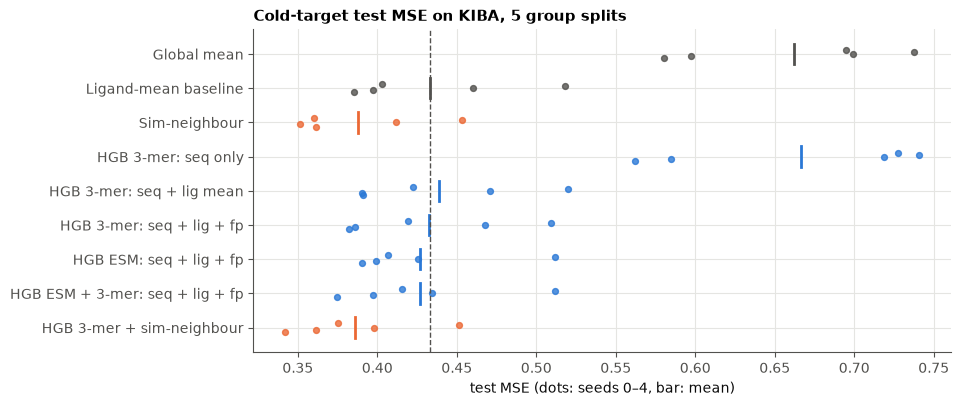

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
show = [m for m in order if m not in ("Random",)]
for i, m in enumerate(show):
    v = wide[m].to_numpy()
    col = INK2 if m in ("Global mean", BASELINE) else (ORANGE if "neighbour" in m else BLUE)
    ax.scatter(v, np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), s=18, color=col, alpha=0.8)
    ax.plot([v.mean()] * 2, [i - 0.3, i + 0.3], color=col, lw=2)
ax.axvline(wide[BASELINE].mean(), color=INK2, ls="--", lw=1)
ax.set_yticks(range(len(show)), show)
ax.invert_yaxis()
ax.set_xlabel("test MSE (dots: seeds 0–4, bar: mean)")
ax.set_title("Cold-target test MSE on KIBA, 5 group splits", loc="left")
savefig(fig, "task3_fig1_test_mse_by_seed")

## 8. Analysis (main split, seed 42)

**(i) Error versus similarity to the training set.** For each test target we take the cosine similarity
of its 3-mer profile to the nearest training target, and bin test rows into 4 quantile bins.

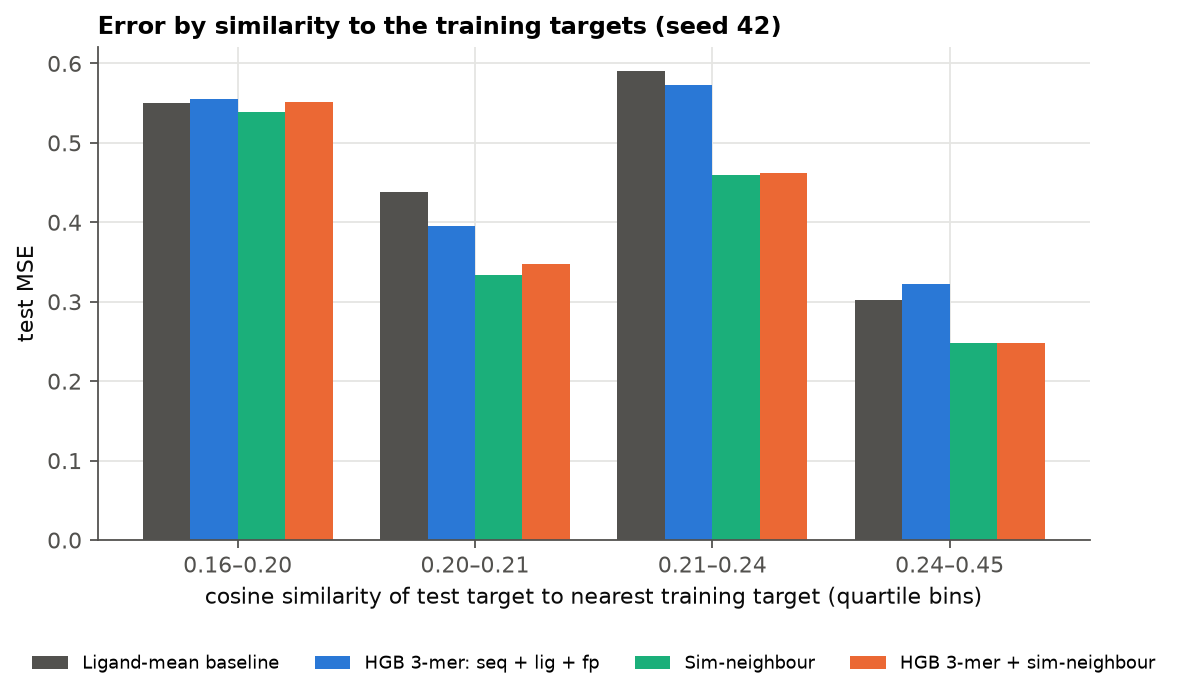

In [14]:
part, preds = main["part"], main["preds"]
te = part == "test"
ft = frame[te].assign(nn3=frame.loc[te, "target_id"].map(main["nn3"]).to_numpy())
ft["bin"] = pd.qcut(ft.nn3, 4)
cmp_models = [BASELINE, "HGB 3-mer: seq + lig + fp", "Sim-neighbour", "HGB 3-mer + sim-neighbour"]
for m in cmp_models:
    ft[m] = (preds[m][te] - ft.y.to_numpy()) ** 2
bins = ft.groupby("bin", observed=True).agg(targets=("target_id", "nunique"), rows=("y", "size"), **{m: (m, "mean") for m in cmp_models})
bins.index = [f"{iv.left:.2f}–{iv.right:.2f}" for iv in bins.index]
bins.index.name = "nearest-train 3-mer cosine"
save_table(bins.reset_index(), "task3_error_vs_similarity")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(bins))
w = 0.2
for j, (m, col) in enumerate(zip(cmp_models, [INK2, BLUE, AQUA, ORANGE])):
    ax.bar(x + (j - 1.5) * w, bins[m], w, color=col, label=m)
ax.set_xticks(x, bins.index)
ax.set_xlabel("cosine similarity of test target to nearest training target (quartile bins)")
ax.set_ylabel("test MSE")
ax.set_title("Error by similarity to the training targets (seed 42)", loc="left")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
savefig(fig, "task3_fig2_error_vs_similarity")

**(ii) Permutation importance of feature groups (validation).** The columns of one group are shuffled
together (5 repeats), and we report the mean increase in validation MSE.

In [15]:
def group_importance(name, n_rep=5):
    m, feats, X = main["models"][name]
    y = frame.y.to_numpy()
    va = part == "val"
    Xv, yv = X[va], y[va]
    base_mse = np.mean((m.predict(Xv) - yv) ** 2)
    widths = [main["blocks"][f].shape[1] for f in feats]
    edges = np.cumsum([0] + widths)
    rng = np.random.default_rng(0)
    out = {}
    for f, a, b in zip(feats, edges[:-1], edges[1:]):
        inc = []
        for _ in range(n_rep):
            Xp = Xv.copy()
            Xp[:, a:b] = Xv[rng.permutation(len(Xv))][:, a:b]
            inc.append(np.mean((m.predict(Xp) - yv) ** 2) - base_mse)
        out[f] = np.mean(inc)
    return out


LABEL = {"seq3": "3-mer profile (+AA, len)", "ligmean": "ligand mean", "fp": "fingerprint",
         "knn": "sim-neighbour prediction", "maxsim": "max similarity"}
imp = pd.DataFrame({n: group_importance(n) for n in ["HGB 3-mer: seq + lig + fp", "HGB 3-mer + sim-neighbour"]})
imp.index = [LABEL[i] for i in imp.index]
imp.index.name = "feature group"
save_table(imp.reset_index(), "task3_permutation_importance")

,feature group,HGB 3-mer: seq + lig + fp,HGB 3-mer + sim-neighbour
0,"3-mer profile (+AA, len)",0.024107,0.007666
1,ligand mean,0.364103,0.012326
2,fingerprint,0.024546,0.012515
3,sim-neighbour prediction,NaN,0.577402
4,max similarity,NaN,-0.017338


**(iii) ESM versus 3-mers, per seed.**

In [16]:
if ESM is not None:
    e = pd.DataFrame({
        "seed": SEEDS,
        "3-mer": wide["HGB 3-mer: seq + lig + fp"].to_numpy(),
        "ESM": wide["HGB ESM: seq + lig + fp"].to_numpy(),
        "ESM + 3-mer": wide["HGB ESM + 3-mer: seq + lig + fp"].to_numpy(),
    })
    e["ESM − 3-mer"] = e["ESM"] - e["3-mer"]
    print(f"ESM beats 3-mer on {(e['ESM − 3-mer'] < 0).sum()} of {len(e)} seeds")
    save_table(e, "task3_esm_vs_kmer")

ESM beats 3-mer on 2 of 5 seeds


## 9. Interpretation

- **Where the gain comes from.** Fig. 2 shows that the neighbour models gain where a test kinase has a
  relative in training: in the middle and top similarity quartiles their error is 15–25 % below the
  baseline. In the least-similar quartile the gain shrinks to about 2 %. Cold-target prediction on
  KIBA works by transfer from related kinases, not by reading a new sequence from scratch.
- **Feature importance.** In the plan's model, the ligand mean dominates (permutation importance 0.36
  against 0.02 for the 3-mer profile and 0.02 for the fingerprint), as on DAVIS. Once the neighbour
  prediction is added, it takes over (0.58) and the ligand mean drops to 0.01. The neighbour prediction
  already contains the ligand's level, adjusted towards its scores on related kinases.
- **ESM vs 3-mers.** Test MSE is nearly identical (ESM better on 2 of 5 splits). Mean-pooled ESM-2 8M
  embeddings do not help here. The global protein embedding mostly encodes "kinase", which all targets are.
- **Why KIBA differs from DAVIS.** On DAVIS the learned models beat the ligand mean on 5 of 5 splits.
  KIBA has 30× more ligands but only 229 targets, all wild-type, so the boosting model sees about 160
  training targets per split to learn a sequence → affinity map. Each ligand has, however, many observed
  training targets, which is exactly what the neighbour predictor exploits.

**Caveats.** Groups are similarity clusters at 0.5, so distant paralogues can still sit on both sides of
the split. The Smith–Waterman matrix is supplied with the data and uses sequences only (no labels), so
using it is legitimate for unseen targets. Large groups decide which targets land in test, and the five
splits share data, so they are not independent. KIBA is 75 % missing, and its scores are a constructed
consensus with heaped values at 11.1/11.2, so "CI > 11.2" is reported alongside the full CI. CI was
computed on at most 20,000 test pairs (fixed seed). Cold-target numbers must not be compared with DeepDTA's
random-split results (MSE 0.194, CI 0.863). Fingerprint: Morgan r = 2, 1,024 count bits (RDKit). ESM:
`facebook/esm2_t6_8M_UR50D`.